# Session 10: Database Integration with Python

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in ['mysql_setup.sql', 'mysql_students_demo.py']:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-10_connect_sqlite.py`

In [2]:
"""
Session 10 · Example 1: connecting Python to a database (SQLite)
----------------------------------------------------------------
The DB-API pattern is the same for SQLite, MySQL, PostgreSQL and SQL Server:
  connect -> cursor -> execute (with parameters) -> fetch / commit -> close
SQLite is built into Python and stores the database in one file (or memory).
Run:  python session-10_connect_sqlite.py
"""
import sqlite3

# 1. Connect (":memory:" = a temporary database in RAM; use "campus.db" for a file)
conn = sqlite3.connect(":memory:")
cur = conn.cursor()
print("SQLite library version:", sqlite3.sqlite_version)

# 2. Create a table (DDL)
cur.execute("""
    CREATE TABLE students (
        id      INTEGER PRIMARY KEY AUTOINCREMENT,
        roll    TEXT    NOT NULL UNIQUE,
        name    TEXT    NOT NULL,
        city    TEXT    DEFAULT 'Karachi',
        cgpa    REAL    CHECK (cgpa BETWEEN 0 AND 4)
    )""")

# 3. Insert rows with PARAMETERS (? placeholders) - never build SQL with f-strings
cur.execute("INSERT INTO students (roll, name, city, cgpa) VALUES (?, ?, ?, ?)",
            ("AI-01", "Ali Khan", "Karachi", 3.1))
print("first insert got id:", cur.lastrowid)
rows = [("AI-02", "Sana Tariq", "Lahore", 3.8), ("AI-03", "Bilal Ahmed", "Karachi", 2.7),
        ("AI-04", "Hira Shah", "Quetta", 3.5), ("AI-05", "Omar Farooq", "Karachi", 3.3)]
cur.executemany("INSERT INTO students (roll, name, city, cgpa) VALUES (?, ?, ?, ?)", rows)
conn.commit()                                     # make the changes permanent
print("rows inserted by executemany:", cur.rowcount)

# 4. Read: fetchone, fetchmany, fetchall
cur.execute("SELECT roll, name, cgpa FROM students ORDER BY cgpa DESC")
print("fetchone :", cur.fetchone())
print("fetchmany:", cur.fetchmany(2))
print("fetchall :", cur.fetchall())

# 5. Parameters in WHERE clauses; named placeholders also work
cur.execute("SELECT name FROM students WHERE city = :city AND cgpa >= :min", {"city": "Karachi", "min": 3.0})
print("Karachi students with CGPA >= 3:", [r[0] for r in cur.fetchall()])

# 6. Rows as dictionaries with row_factory
conn.row_factory = sqlite3.Row
row = conn.execute("SELECT * FROM students WHERE roll = ?", ("AI-04",)).fetchone()
print("sqlite3.Row:", dict(row), "| access by name:", row["name"])
conn.row_factory = None

# 7. Update and delete report how many rows changed
cur.execute("UPDATE students SET cgpa = cgpa + 0.1 WHERE city = ?", ("Karachi",))
print("updated rows:", cur.rowcount)
cur.execute("DELETE FROM students WHERE roll = ?", ("AI-03",))
print("deleted rows:", cur.rowcount)
conn.commit()

# 8. Constraint violations raise exceptions you can handle
for bad in [("AI-01", "Duplicate Roll", "Karachi", 3.0), ("AI-09", "Too High", "Karachi", 4.7)]:
    try:
        cur.execute("INSERT INTO students (roll, name, city, cgpa) VALUES (?, ?, ?, ?)", bad)
    except sqlite3.IntegrityError as e:
        print("IntegrityError:", e)

# 9. Aggregates
cur.execute("SELECT city, COUNT(*), ROUND(AVG(cgpa), 2) FROM students GROUP BY city ORDER BY 2 DESC, city")
print("by city:", cur.fetchall())

# 10. Why parameters matter: SQL injection
attack = "x' OR '1'='1"
unsafe_sql = f"SELECT COUNT(*) FROM students WHERE name = '{attack}'"      # DON'T do this
print("\nunsafe query text:", unsafe_sql)
print("  rows matched by the UNSAFE query:", cur.execute(unsafe_sql).fetchone()[0], "<- attacker sees everything")
print("  rows matched with a parameter   :", cur.execute("SELECT COUNT(*) FROM students WHERE name = ?", (attack,)).fetchone()[0])

conn.close()
print("connection closed")

SQLite library version: 3.46.1
first insert got id: 1
rows inserted by executemany: 4
fetchone : ('AI-02', 'Sana Tariq', 3.8)
fetchmany: [('AI-04', 'Hira Shah', 3.5), ('AI-05', 'Omar Farooq', 3.3)]
fetchall : [('AI-01', 'Ali Khan', 3.1), ('AI-03', 'Bilal Ahmed', 2.7)]
Karachi students with CGPA >= 3: ['Ali Khan', 'Omar Farooq']
sqlite3.Row: {'id': 4, 'roll': 'AI-04', 'name': 'Hira Shah', 'city': 'Quetta', 'cgpa': 3.5} | access by name: Hira Shah
updated rows: 3
deleted rows: 1
IntegrityError: UNIQUE constraint failed: students.roll
IntegrityError: CHECK constraint failed: cgpa BETWEEN 0 AND 4
by city: [('Karachi', 2, 3.3), ('Lahore', 1, 3.8), ('Quetta', 1, 3.5)]

unsafe query text: SELECT COUNT(*) FROM students WHERE name = 'x' OR '1'='1'
  rows matched by the UNSAFE query: 4 <- attacker sees everything
  rows matched with a parameter   : 0
connection closed


## Example: `session-10_crud_repository.py`

In [3]:
"""
Session 10 · Example 2: a data-access layer with CRUD functions and transactions
--------------------------------------------------------------------------------
Wrapping all SQL in one class (a "repository") keeps the rest of the program
free of SQL and makes it easy to switch from SQLite to MySQL later.
Run:  python session-10_crud_repository.py
"""
import sqlite3
from contextlib import closing

class StudentRepository:
    def __init__(self, path=":memory:"):
        self.conn = sqlite3.connect(path)
        self.conn.row_factory = sqlite3.Row
        self.conn.execute("PRAGMA foreign_keys = ON")
        self.conn.executescript("""
            CREATE TABLE IF NOT EXISTS students (
                roll TEXT PRIMARY KEY, name TEXT NOT NULL, phone TEXT, cgpa REAL CHECK (cgpa BETWEEN 0 AND 4));
            CREATE TABLE IF NOT EXISTS fees (
                id INTEGER PRIMARY KEY, roll TEXT NOT NULL REFERENCES students(roll) ON DELETE CASCADE,
                amount INTEGER NOT NULL CHECK (amount > 0), paid_on TEXT NOT NULL);
        """)

    # ----- Create -----
    def add(self, roll, name, phone=None, cgpa=None):
        with self.conn:                                   # commits on success, rolls back on error
            self.conn.execute("INSERT INTO students VALUES (?, ?, ?, ?)", (roll, name, phone, cgpa))

    # ----- Read -----
    def get(self, roll):
        row = self.conn.execute("SELECT * FROM students WHERE roll = ?", (roll,)).fetchone()
        return dict(row) if row else None

    def search(self, text="", min_cgpa=0.0):
        sql = "SELECT * FROM students WHERE name LIKE ? AND IFNULL(cgpa, 0) >= ? ORDER BY name"
        return [dict(r) for r in self.conn.execute(sql, (f"%{text}%", min_cgpa))]

    # ----- Update -----
    def update(self, roll, /, **fields):          # '/' lets 'roll' also appear in **fields
        allowed = {"name", "phone", "cgpa"}
        if not fields or not set(fields) <= allowed:      # e.g. changing the primary key is refused
            raise ValueError(f"can only update {sorted(allowed)}")
        sets = ", ".join(f"{k} = ?" for k in fields)          # column names come from our whitelist
        with self.conn:
            cur = self.conn.execute(f"UPDATE students SET {sets} WHERE roll = ?", (*fields.values(), roll))
        return cur.rowcount

    # ----- Delete -----
    def delete(self, roll):
        with self.conn:
            return self.conn.execute("DELETE FROM students WHERE roll = ?", (roll,)).rowcount

    # ----- A transaction across two tables -----
    def pay_fee_instalments(self, roll, amounts, day):
        """All instalments are recorded, or none are (atomicity)."""
        with self.conn:
            for amt in amounts:
                self.conn.execute("INSERT INTO fees (roll, amount, paid_on) VALUES (?, ?, ?)", (roll, amt, day))

    def fee_report(self):
        sql = """SELECT s.roll, s.name, COUNT(f.id) AS payments, IFNULL(SUM(f.amount), 0) AS total
                 FROM students s LEFT JOIN fees f ON f.roll = s.roll GROUP BY s.roll ORDER BY total DESC"""
        return [dict(r) for r in self.conn.execute(sql)]

repo = StudentRepository()
for r in [("AI-01", "Ali Khan", "0300-1111111", 3.1), ("AI-02", "Sana Tariq", "0321-2222222", 3.8),
          ("AI-03", "Bilal Ahmed", None, 2.7), ("AI-04", "Hira Shah", "0333-4444444", 3.5)]:
    repo.add(*r)
print("get AI-02     :", repo.get("AI-02"))
print("search 'a', cgpa>=3.2:", [s["name"] for s in repo.search("a", 3.2)])
print("update phone  :", repo.update("AI-03", phone="0345-3333333"), "row(s)")
try:
    repo.update("AI-03", roll="AI-99")
except ValueError as e:
    print("update refused:", e)
try:
    repo.add("AI-01", "Someone Else")
except sqlite3.IntegrityError as e:
    print("add refused   :", e)

repo.pay_fee_instalments("AI-01", [25_000, 25_000], "2026-10-01")
try:
    repo.pay_fee_instalments("AI-02", [30_000, -5], "2026-10-02")    # second amount breaks the CHECK
except sqlite3.IntegrityError as e:
    print("transaction rolled back:", e)
print("fee report    :", repo.fee_report())
print("delete AI-01  :", repo.delete("AI-01"), "row(s); its fee rows cascade ->",
      repo.conn.execute("SELECT COUNT(*) FROM fees").fetchone()[0], "fee rows left")
with closing(repo.conn):
    print("students left :", [s["roll"] for s in repo.search()])

get AI-02     : {'roll': 'AI-02', 'name': 'Sana Tariq', 'phone': '0321-2222222', 'cgpa': 3.8}
search 'a', cgpa>=3.2: ['Hira Shah', 'Sana Tariq']
update phone  : 1 row(s)
update refused: can only update ['cgpa', 'name', 'phone']
add refused   : UNIQUE constraint failed: students.roll
transaction rolled back: CHECK constraint failed: amount > 0
fee report    : [{'roll': 'AI-01', 'name': 'Ali Khan', 'payments': 2, 'total': 50000}, {'roll': 'AI-02', 'name': 'Sana Tariq', 'payments': 0, 'total': 0}, {'roll': 'AI-03', 'name': 'Bilal Ahmed', 'payments': 0, 'total': 0}, {'roll': 'AI-04', 'name': 'Hira Shah', 'payments': 0, 'total': 0}]
delete AI-01  : 1 row(s); its fee rows cascade -> 0 fee rows left
students left : ['AI-03', 'AI-04', 'AI-02']


## Example: `session-10_problem_library_db.py`

In [4]:
"""
Session 10 · Real-life problem: a library management database
-------------------------------------------------------------
PROBLEM
The department library tracks books on paper. Design and code a database that
  1. has three related tables: books, members, loans (with foreign keys),
  2. lets a member BORROW a book only if a copy is available and they have
     fewer than 3 active loans - inside a transaction,
  3. RETURNS books and charges Rs 20 per late day (14-day loan period),
  4. reports overdue loans (JOIN) and the most borrowed categories, with a chart.
Run:  python session-10_problem_library_db.py
"""
import sqlite3
from datetime import date, timedelta

LOAN_DAYS, FINE_PER_DAY, MAX_LOANS = 14, 20, 3

db = sqlite3.connect(":memory:")
db.row_factory = sqlite3.Row
db.execute("PRAGMA foreign_keys = ON")
db.executescript("""
CREATE TABLE books   (id INTEGER PRIMARY KEY, title TEXT NOT NULL, category TEXT NOT NULL,
                      copies INTEGER NOT NULL CHECK (copies >= 0));
CREATE TABLE members (id INTEGER PRIMARY KEY, name TEXT NOT NULL, kind TEXT CHECK (kind IN ('student','staff')));
CREATE TABLE loans   (id INTEGER PRIMARY KEY, book_id INTEGER NOT NULL REFERENCES books(id),
                      member_id INTEGER NOT NULL REFERENCES members(id),
                      borrowed TEXT NOT NULL, due TEXT NOT NULL, returned TEXT, fine INTEGER DEFAULT 0);
""")
db.executemany("INSERT INTO books VALUES (?, ?, ?, ?)", [
    (1, "Python Crash Course", "programming", 2), (2, "Think Stats", "statistics", 1),
    (3, "Hands-On Machine Learning", "ai", 2), (4, "Database System Concepts", "databases", 1),
    (5, "Automate the Boring Stuff", "programming", 1)])
db.executemany("INSERT INTO members VALUES (?, ?, ?)", [
    (1, "Ayesha", "student"), (2, "Omar", "student"), (3, "Mr Kamran", "staff")])
db.commit()

class LibraryError(Exception):
    pass

def borrow(member_id, book_id, day):
    """Check the rules and record a loan atomically."""
    with db:                                             # one transaction
        book = db.execute("SELECT title, copies FROM books WHERE id = ?", (book_id,)).fetchone()
        if book is None:
            raise LibraryError(f"no book with id {book_id}")
        active = db.execute("SELECT COUNT(*) FROM loans WHERE member_id = ? AND returned IS NULL",
                            (member_id,)).fetchone()[0]
        if active >= MAX_LOANS:
            raise LibraryError(f"member {member_id} already has {active} books")
        if book["copies"] == 0:
            raise LibraryError(f"'{book['title']}' is not available")
        db.execute("UPDATE books SET copies = copies - 1 WHERE id = ?", (book_id,))
        db.execute("INSERT INTO loans (book_id, member_id, borrowed, due) VALUES (?, ?, ?, ?)",
                   (book_id, member_id, day.isoformat(), (day + timedelta(days=LOAN_DAYS)).isoformat()))
    return book["title"]

def give_back(loan_id, day):
    with db:
        loan = db.execute("SELECT * FROM loans WHERE id = ? AND returned IS NULL", (loan_id,)).fetchone()
        if loan is None:
            raise LibraryError(f"loan {loan_id} is not open")
        late = max(0, (day - date.fromisoformat(loan["due"])).days)
        db.execute("UPDATE loans SET returned = ?, fine = ? WHERE id = ?", (day.isoformat(), late * FINE_PER_DAY, loan_id))
        db.execute("UPDATE books SET copies = copies + 1 WHERE id = ?", (loan["book_id"],))
    return late * FINE_PER_DAY

d = date(2026, 9, 1)
events = [("borrow", 1, 1, d), ("borrow", 1, 2, d), ("borrow", 2, 2, d + timedelta(1)),
          ("borrow", 1, 3, d + timedelta(2)), ("borrow", 1, 4, d + timedelta(2)), ("borrow", 3, 3, d + timedelta(3)),
          ("borrow", 2, 1, d + timedelta(5)), ("borrow", 3, 5, d + timedelta(6)), ("borrow", 2, 9, d + timedelta(6))]
for kind, member, book, day in events:
    try:
        print(f"{day} member {member} borrows '{borrow(member, book, day)}'")
    except LibraryError as e:
        print(f"{day} member {member} REFUSED: {e}")

for loan_id, day in [(1, date(2026, 9, 10)), (2, date(2026, 9, 20)), (2, date(2026, 9, 21))]:
    try:
        print(f"{day} loan {loan_id} returned, fine Rs {give_back(loan_id, day)}")
    except LibraryError as e:
        print(f"{day} REFUSED: {e}")

today = date(2026, 9, 25)
print(f"\nOverdue on {today}:")
sql = """SELECT m.name, b.title, l.due, julianday(?) - julianday(l.due) AS days_late
         FROM loans l JOIN members m ON m.id = l.member_id JOIN books b ON b.id = l.book_id
         WHERE l.returned IS NULL AND l.due < ? ORDER BY days_late DESC"""
for r in db.execute(sql, (today.isoformat(), today.isoformat())):
    print(f"  {r['name']:<9} {r['title']:<28} due {r['due']}  {int(r['days_late'])} days late "
          f"(fine so far Rs {int(r['days_late']) * FINE_PER_DAY})")

print("\nAvailability:", [(r["title"][:22], r["copies"]) for r in db.execute("SELECT title, copies FROM books")])
cats = db.execute("""SELECT b.category, COUNT(*) AS loans FROM loans l JOIN books b ON b.id = l.book_id
                     GROUP BY b.category ORDER BY loans DESC, b.category""").fetchall()
print("Loans by category:", [(c["category"], c["loans"]) for c in cats])
print("Fines collected: Rs", db.execute("SELECT SUM(fine) FROM loans").fetchone()[0])

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar([c["category"] for c in cats], [c["loans"] for c in cats], color="#A78BFA")
ax.set_ylabel("loans"); ax.set_title("Which subjects do members borrow most?")
fig.tight_layout(); fig.savefig("session-10_problem_library_db.png", dpi=110)
print("Chart saved: session-10_problem_library_db.png")

2026-09-01 member 1 borrows 'Python Crash Course'
2026-09-01 member 1 borrows 'Think Stats'
2026-09-02 member 2 REFUSED: 'Think Stats' is not available
2026-09-03 member 1 borrows 'Hands-On Machine Learning'
2026-09-03 member 1 REFUSED: member 1 already has 3 books
2026-09-04 member 3 borrows 'Hands-On Machine Learning'
2026-09-06 member 2 borrows 'Python Crash Course'
2026-09-07 member 3 borrows 'Automate the Boring Stuff'
2026-09-07 member 2 REFUSED: no book with id 9
2026-09-10 loan 1 returned, fine Rs 0
2026-09-20 loan 2 returned, fine Rs 100
2026-09-21 REFUSED: loan 2 is not open

Overdue on 2026-09-25:
  Ayesha    Hands-On Machine Learning    due 2026-09-17  8 days late (fine so far Rs 160)
  Mr Kamran Hands-On Machine Learning    due 2026-09-18  7 days late (fine so far Rs 140)
  Omar      Python Crash Course          due 2026-09-20  5 days late (fine so far Rs 100)
  Mr Kamran Automate the Boring Stuff    due 2026-09-21  4 days late (fine so far Rs 80)

Availability: [('Python 

Chart saved: session-10_problem_library_db.png


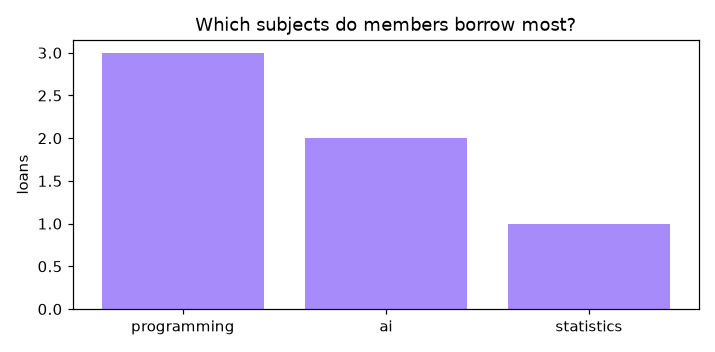

In [5]:
from IPython.display import Image, display
display(Image(filename='session-10_problem_library_db.png'))  # chart saved by the cell above

## Example: `session-10_project_student_manager.py`

In [6]:
"""
Session 10 · Mini project: a student records manager (Tkinter + SQLite CRUD)
---------------------------------------------------------------------------
A desktop app to INSERT, UPDATE, DELETE and SEARCH student records stored in
a SQLite database file (students.db).
  - StudentDB   : all SQL (parameterised queries, transactions, validation)
  - StudentApp  : the Tkinter window (form + Treeview table + buttons)
Clicking a row in the table loads it into the form for editing.
Run:  python session-10_project_student_manager.py
(no screen? it runs the same database operations in test mode)
"""
import os
import re
import sqlite3
from gui_support import gui_available, banner

class StudentDB:
    FIELDS = ("roll", "name", "program", "phone", "cgpa")

    def __init__(self, path="students.db"):
        self.conn = sqlite3.connect(path)
        self.conn.row_factory = sqlite3.Row
        self.conn.execute("""CREATE TABLE IF NOT EXISTS students (
            roll TEXT PRIMARY KEY, name TEXT NOT NULL, program TEXT NOT NULL,
            phone TEXT, cgpa REAL CHECK (cgpa BETWEEN 0 AND 4))""")
        self.conn.commit()

    @staticmethod
    def validate(rec):
        errors = []
        if not re.fullmatch(r"AI-\d{2}", rec["roll"]): errors.append("roll must look like AI-07")
        if len(rec["name"].strip()) < 3: errors.append("name is too short")
        if rec["phone"] and not re.fullmatch(r"03\d{2}-\d{7}", rec["phone"]): errors.append("phone must be 03XX-XXXXXXX")
        try:
            if not 0 <= float(rec["cgpa"]) <= 4: errors.append("CGPA must be 0-4")
        except ValueError:
            errors.append("CGPA must be a number")
        if errors:
            raise ValueError("; ".join(errors))
        return {**rec, "name": rec["name"].strip().title(), "cgpa": round(float(rec["cgpa"]), 2)}

    def insert(self, rec):
        rec = self.validate(rec)
        try:
            with self.conn:
                self.conn.execute("INSERT INTO students VALUES (:roll, :name, :program, :phone, :cgpa)", rec)
        except sqlite3.IntegrityError:
            raise ValueError(f"roll {rec['roll']} already exists") from None

    def update(self, rec):
        rec = self.validate(rec)
        with self.conn:
            n = self.conn.execute("""UPDATE students SET name=:name, program=:program, phone=:phone, cgpa=:cgpa
                                     WHERE roll=:roll""", rec).rowcount
        if n == 0:
            raise ValueError(f"roll {rec['roll']} not found")

    def delete(self, roll):
        with self.conn:
            if self.conn.execute("DELETE FROM students WHERE roll = ?", (roll,)).rowcount == 0:
                raise ValueError(f"roll {roll} not found")

    def search(self, text=""):
        like = f"%{text}%"
        return [dict(r) for r in self.conn.execute(
            "SELECT * FROM students WHERE roll LIKE ? OR name LIKE ? OR program LIKE ? ORDER BY roll",
            (like, like, like))]

    def stats(self):
        r = self.conn.execute("SELECT COUNT(*) n, ROUND(AVG(cgpa), 2) avg, MAX(cgpa) best FROM students").fetchone()
        return dict(r)

def run_gui(db):
    import tkinter as tk
    from tkinter import ttk, messagebox
    root = tk.Tk(); root.title("Student records")
    form = tk.LabelFrame(root, text="Student", padx=8, pady=6); form.pack(fill="x", padx=8, pady=6)
    vars_ = {f: tk.StringVar() for f in StudentDB.FIELDS}
    for r, f in enumerate(StudentDB.FIELDS):
        tk.Label(form, text=f.title()).grid(row=r, column=0, sticky="w")
        if f == "program":
            ttk.Combobox(form, textvariable=vars_[f], values=["Diploma in AI", "Data Science", "Web Development"],
                         state="readonly", width=27).grid(row=r, column=1, pady=2)
        else:
            tk.Entry(form, textvariable=vars_[f], width=30).grid(row=r, column=1, pady=2)
    buttons = tk.Frame(root); buttons.pack(fill="x", padx=8)
    search = tk.StringVar()
    table = ttk.Treeview(root, columns=StudentDB.FIELDS, show="headings", height=8)
    for f in StudentDB.FIELDS:
        table.heading(f, text=f.title()); table.column(f, width=110)
    table.pack(fill="both", expand=True, padx=8, pady=6)
    status = tk.Label(root, anchor="w", relief="sunken"); status.pack(fill="x", side="bottom")

    def record():
        return {f: v.get().strip() for f, v in vars_.items()}
    def refresh():
        table.delete(*table.get_children())
        for s in db.search(search.get()):
            table.insert("", "end", iid=s["roll"], values=[s[f] for f in StudentDB.FIELDS])
        st = db.stats(); status.config(text=f"{st['n']} students | average CGPA {st['avg']} | best {st['best']}")
    def action(fn, ok_msg):
        try:
            fn(); refresh(); status.config(text=ok_msg)
        except ValueError as e:
            messagebox.showerror("Cannot save", str(e))
    def on_select(_event):
        sel = table.selection()
        if sel:
            for f, value in zip(StudentDB.FIELDS, table.item(sel[0])["values"]):
                vars_[f].set(value)
    def clear():
        for v in vars_.values(): v.set("")
    for text, cmd in [("Insert", lambda: action(lambda: db.insert(record()), "Inserted")),
                      ("Update", lambda: action(lambda: db.update(record()), "Updated")),
                      ("Delete", lambda: messagebox.askyesno("Delete", "Delete this student?")
                                 and action(lambda: db.delete(vars_["roll"].get()), "Deleted")),
                      ("Clear", clear)]:
        tk.Button(buttons, text=text, width=9, command=cmd).pack(side="left", padx=2)
    tk.Entry(buttons, textvariable=search, width=16).pack(side="right")
    tk.Label(buttons, text="Search").pack(side="right")
    search.trace_add("write", lambda *_: refresh())          # live search while typing
    table.bind("<<TreeviewSelect>>", on_select)
    refresh(); root.mainloop()

if gui_available():
    run_gui(StudentDB())
else:
    banner("student_manager")
    path = "students_demo.db"
    if os.path.exists(path): os.remove(path)
    db = StudentDB(path)
    def show(label, fn):
        try:
            fn(); print(f"{label:<44} ok")
        except ValueError as e:
            print(f"{label:<44} error: {e}")
    rec = lambda roll, name, prog, phone, cgpa: dict(roll=roll, name=name, program=prog, phone=phone, cgpa=cgpa)
    show("Insert AI-01 ayesha siddiqui", lambda: db.insert(rec("AI-01", "ayesha siddiqui", "Diploma in AI", "0321-7654321", "3.72")))
    show("Insert AI-02 Omar Farooq", lambda: db.insert(rec("AI-02", "Omar Farooq", "Data Science", "", "3.1")))
    show("Insert AI-03 Hira Shah", lambda: db.insert(rec("AI-03", "Hira Shah", "Diploma in AI", "0333-4444444", "3.45")))
    show("Insert AI-01 again", lambda: db.insert(rec("AI-01", "Someone", "Data Science", "", "2.0")))
    show("Insert bad form", lambda: db.insert(rec("7", "Al", "Diploma in AI", "12345", "five")))
    show("Update AI-02 cgpa -> 3.35", lambda: db.update(rec("AI-02", "Omar Farooq", "Data Science", "0300-1112233", "3.35")))
    show("Update AI-09 (does not exist)", lambda: db.update(rec("AI-09", "Nobody Here", "Data Science", "", "2")))
    print("\nTable (search ''):")
    for s in db.search():
        print(f"  {s['roll']}  {s['name']:<16} {s['program']:<14} {s['phone'] or '-':<13} {s['cgpa']}")
    print("Search 'diploma':", [s["roll"] for s in db.search("diploma")])
    show("Delete AI-03", lambda: db.delete("AI-03"))
    print("Status bar:", db.stats())
    db.conn.close()
    reopened = StudentDB(path)              # data is really on disk
    print("After reopening the database file:", [s["roll"] for s in reopened.search()])
    reopened.conn.close(); os.remove(path)

[student_manager] no screen available here -> running the app logic in test mode.
Run this file on your own computer (python <file>.py) to see the window.

Insert AI-01 ayesha siddiqui                 ok
Insert AI-02 Omar Farooq                     ok
Insert AI-03 Hira Shah                       ok
Insert AI-01 again                           error: roll AI-01 already exists
Insert bad form                              error: roll must look like AI-07; name is too short; phone must be 03XX-XXXXXXX; CGPA must be a number
Update AI-02 cgpa -> 3.35                    ok
Update AI-09 (does not exist)                error: roll AI-09 not found

Table (search ''):
  AI-01  Ayesha Siddiqui  Diploma in AI  0321-7654321  3.72
  AI-02  Omar Farooq      Data Science   0300-1112233  3.35
  AI-03  Hira Shah        Diploma in AI  0333-4444444  3.45
Search 'diploma': ['AI-01', 'AI-03']
Delete AI-03                                 ok
Status bar: {'n': 2, 'avg': 3.54, 'best': 3.72}
After reopening the 